# Notebook 02 - Linear Regression 2.1: predicting the goal difference of a match
**Sydney Group 19 - Assessment 3 (Objective 2)**

**Analytic question:** *Using only information available before kick-off, how well can a linear
model predict the final goal difference (Team A - Team B) of a FIFA World Cup 2026 match, and which
pre-match factors drive it?*

**Workflow**
1. Exploratory analysis of the 104-match dataset
2. Multicollinearity check (VIF)
3. Full-sample OLS with statistical inference (coefficients, 95% CI, p-values)
4. **Competing algorithms** evaluated on identical repeated 10-fold CV splits:
   mean baseline, strength-only OLS, full OLS, Ridge, Lasso, Elastic Net, Huber (robust)
5. Statistical comparison of models (Nadeau-Bengio corrected paired t-test)
6. Out-of-time test: train on the group stage, test on the knockout stage
7. Residual diagnostics and the biggest "upsets"
8. Recommendation

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import (LinearRegression, RidgeCV, LassoCV, ElasticNetCV,
                                  HuberRegressor, lasso_path)
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from wc_utils import (OLSInference, vif, cross_validate_models, summarise_cv,
                      corrected_paired_ttest, outcome_accuracy)

os.makedirs("../figures", exist_ok=True); os.makedirs("../results", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
C = {"main": "#1f4e79", "accent": "#d1495b", "grey": "#8c8c8c", "green": "#2a9d8f", "gold": "#e9a03b"}

df = pd.read_csv("../data/processed/lr21_match_level.csv")
FEAT = ["strength_diff", "form_gd_diff", "host_diff", "rest_diff", "travel_diff_1000km",
        "home_dist_diff_1000km", "wc_exp_diff", "elite_confed_diff"]
TARGET = "goal_diff"
X, y = df[FEAT], df[TARGET]
print(df.shape, "| explanatory variables:", len(FEAT))

(104, 13) | explanatory variables: 8


## 1. Exploratory data analysis

In [2]:
print(y.describe().round(2))
print("Share of draws (GD = 0):", round((y == 0).mean(), 3))
print("Skewness:", round(stats.skew(y), 3))
corr = df[FEAT + [TARGET]].corr()
corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3)

count    104.00
mean       0.48
std        2.02
min       -4.00
25%       -1.00
50%        0.00
75%        2.00
max        6.00
Name: goal_diff, dtype: float64
Share of draws (GD = 0): 0.231
Skewness: 0.254


strength_diff            0.629
wc_exp_diff              0.533
form_gd_diff             0.328
elite_confed_diff        0.316
home_dist_diff_1000km   -0.217
host_diff                0.160
travel_diff_1000km      -0.126
rest_diff               -0.034
Name: goal_diff, dtype: float64

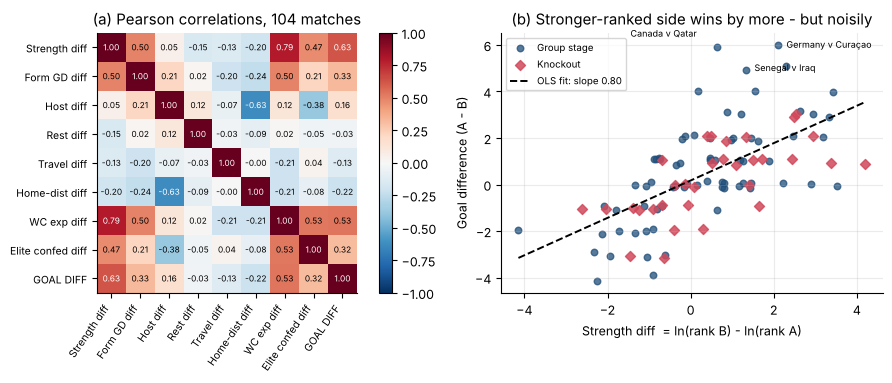

In [3]:
labels = {"strength_diff": "Strength diff", "form_gd_diff": "Form GD diff", "host_diff": "Host diff",
          "rest_diff": "Rest diff", "travel_diff_1000km": "Travel diff", "home_dist_diff_1000km": "Home-dist diff",
          "wc_exp_diff": "WC exp diff", "elite_confed_diff": "Elite confed diff", "goal_diff": "GOAL DIFF"}
fig, ax = plt.subplots(1, 2, figsize=(10, 3.9), gridspec_kw={"width_ratios": [1.15, 1]})
im = ax[0].imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax[0].set_xticks(range(9)); ax[0].set_yticks(range(9))
ax[0].set_xticklabels([labels[c] for c in corr.columns], rotation=55, ha="right", fontsize=7.5)
ax[0].set_yticklabels([labels[c] for c in corr.columns], fontsize=7.5)
for i in range(9):
    for j in range(9):
        ax[0].text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=6,
                   color="white" if abs(corr.values[i, j]) > 0.55 else "black")
ax[0].grid(False); ax[0].set_title("(a) Pearson correlations, 104 matches")
fig.colorbar(im, ax=ax[0], fraction=0.04)
ko = df.stage.str.startswith("Group") == False
jit = np.random.default_rng(1).uniform(-0.15, 0.15, len(df))
ax[1].scatter(df.strength_diff[~ko], y[~ko] + jit[~ko], s=22, alpha=.75, c=C["main"], label="Group stage")
ax[1].scatter(df.strength_diff[ko], y[ko] + jit[ko], s=26, alpha=.85, c=C["accent"], marker="D", label="Knockout")
b1, b0 = np.polyfit(df.strength_diff, y, 1)
xs = np.linspace(df.strength_diff.min(), df.strength_diff.max(), 50)
ax[1].plot(xs, b0 + b1 * xs, c="black", lw=1.4, ls="--", label=f"OLS fit: slope {b1:.2f}")
offs = [(-62, 6), (6, -2), (6, -2)]
for (_, r), o in zip(df.loc[(y - (b0 + b1 * df.strength_diff)).abs().nlargest(3).index].iterrows(), offs):
    ax[1].annotate(f"{r.team_a} v {r.team_b}", (r.strength_diff, r.goal_diff), fontsize=6.5,
                   xytext=o, textcoords="offset points")
ax[1].set_xlabel("Strength diff  = ln(rank B) - ln(rank A)"); ax[1].set_ylabel("Goal difference (A - B)")
ax[1].set_title("(b) Stronger-ranked side wins by more - but noisily"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig("../figures/fig1_lr21_eda.png", dpi=200, bbox_inches="tight"); plt.show()

## 2. Multicollinearity (VIF)
VIF > 5 would signal unstable coefficients; all values are well below that threshold.

In [4]:
v = vif(X).round(2); v

strength_diff            3.12
form_gd_diff             1.47
host_diff                2.87
rest_diff                1.09
travel_diff_1000km       1.10
home_dist_diff_1000km    2.14
wc_exp_diff              3.74
elite_confed_diff        2.43
Name: VIF, dtype: float64

## 3. Full-sample OLS with inference
Fitted on all 104 matches to *explain* (coefficients, CIs, p-values). Predictive performance is assessed
separately with cross-validation in Section 4, because in-sample R2 is optimistic.

In [5]:
ols = OLSInference().fit(X, y)
coef_table = ols.summary(); coef_table

n = 104, predictors = 8
R2 = 0.425   adj R2 = 0.376   F = 8.77 (p = 6.63e-09)   AIC = 401.3   BIC = 425.1


,coef,std_err,t,p_value,ci_low,ci_high
const,0.0656,0.1716,0.3820,0.7033,-0.2751,0.4062
strength_diff,0.7610,0.1755,4.3351,0.0000,0.4125,1.1095
form_gd_diff,-0.0553,0.1650,-0.3355,0.7380,-0.3829,0.2722
host_diff,1.1735,0.7647,1.5346,0.1282,-0.3446,2.6916
rest_diff,0.1538,0.3126,0.4919,0.6239,-0.4668,0.7744
travel_diff_1000km,-0.0787,0.1364,-0.5774,0.5651,-0.3495,0.1920
home_dist_diff_1000km,0.0140,0.0548,0.2548,0.7995,-0.0949,0.1228
wc_exp_diff,-0.0062,0.0351,-0.1772,0.8597,-0.0759,0.0634
elite_confed_diff,0.3765,0.3284,1.1465,0.2545,-0.2754,1.0284


**Standardised coefficients** (effect of +1 SD of each predictor, in goals) make the predictors comparable.

In [6]:
std_coef = (coef_table.loc[FEAT, ["coef", "ci_low", "ci_high"]].mul(X.std(), axis=0)).round(3)
std_coef["p_value"] = coef_table.loc[FEAT, "p_value"].round(4)
std_coef.sort_values("coef", key=abs, ascending=False)

,coef,ci_low,ci_high,p_value
strength_diff,1.206,0.654,1.758,0.0000
host_diff,0.409,-0.120,0.939,0.1282
elite_confed_diff,0.281,-0.206,0.769,0.2545
travel_diff_1000km,-0.095,-0.424,0.233,0.5651
rest_diff,0.081,-0.246,0.408,0.6239
form_gd_diff,-0.064,-0.443,0.315,0.7380
home_dist_diff_1000km,0.059,-0.399,0.517,0.7995
wc_exp_diff,-0.054,-0.659,0.551,0.8597


## 4. Competing algorithms - repeated 10-fold cross-validation (10 x 10 = 100 folds)
All models are wrapped in a pipeline with `StandardScaler`, so scaling is learned **inside** each
training fold (no leakage). Regularisation strength for Ridge/Lasso/Elastic Net is tuned by an inner CV.
Every model sees exactly the same 100 train/test splits, so their scores can be compared pairwise.

In [7]:
alphas = np.logspace(-3, 2, 60)
models = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "OLS strength only": make_pipeline(StandardScaler(), LinearRegression()),
    "OLS (8 vars)": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=alphas)),
    "Lasso": make_pipeline(StandardScaler(), LassoCV(alphas=alphas, cv=5, max_iter=50000, random_state=0)),
    "Elastic Net": make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[.2, .5, .8], alphas=alphas, cv=5,
                                                                max_iter=50000, random_state=0)),
    "Huber (robust)": make_pipeline(StandardScaler(), HuberRegressor(epsilon=1.35, max_iter=2000)),
}
from sklearn.base import BaseEstimator, RegressorMixin, clone
class FirstColumn(BaseEstimator, RegressorMixin):
    """Fits the wrapped model on column 0 only (strength_diff) - a one-variable benchmark."""
    def __init__(self, model): self.model = model
    def fit(self, X, y): self.m_ = clone(self.model).fit(X[:, [0]], y); return self
    def predict(self, X): return self.m_.predict(X[:, [0]])
models["OLS strength only"] = FirstColumn(make_pipeline(StandardScaler(), LinearRegression()))

scores = cross_validate_models(models, X.values, y.values, groups=df.match_id, n_splits=10,
                               n_repeats=10, seed=42, extra_metrics={"Outcome_acc": outcome_accuracy})
cv_table = summarise_cv(scores, metrics=("RMSE", "MAE", "R2", "Outcome_acc"))
cv_table

,RMSE,MAE,R2,Outcome_acc,RMSE_sd,MAE_sd,R2_sd,Outcome_acc_sd
model,,,,,,,,
OLS strength only,1.540,1.233,0.270,0.628,0.416,0.335,0.366,0.142
Lasso,1.586,1.259,0.242,0.577,0.419,0.336,0.299,0.146
Elastic Net,1.593,1.265,0.235,0.582,0.418,0.335,0.308,0.146
Ridge,1.641,1.318,0.178,0.556,0.410,0.331,0.343,0.147
OLS (8 vars),1.647,1.318,0.156,0.596,0.415,0.341,0.398,0.149
Huber (robust),1.660,1.344,0.147,0.581,0.407,0.344,0.386,0.155
Baseline (mean),1.983,1.591,-0.142,0.281,0.443,0.373,0.217,0.137


### 4.1 Are the differences statistically real?
Naive paired t-tests over CV folds are over-confident because training sets overlap. We use the
**Nadeau-Bengio corrected resampled t-test** (n_train/n_test about 9).

In [8]:
piv = scores.pivot_table(index=["repeat", scores.groupby(["model", "repeat"]).cumcount()],
                         columns="model", values="RMSE")
rows = []
for a_, b_ in [("OLS (8 vars)", "Baseline (mean)"), ("Ridge", "Baseline (mean)"),
               ("Ridge", "OLS (8 vars)"), ("Lasso", "OLS (8 vars)"), ("Huber (robust)", "OLS (8 vars)"),
               ("OLS (8 vars)", "OLS strength only"), ("Ridge", "OLS strength only")]:
    d, t, p = corrected_paired_ttest(piv[a_], piv[b_], n_train=94, n_test=10)
    rows.append({"model A": a_, "model B": b_, "mean RMSE(A-B)": round(d, 4), "t": round(t, 2), "p": round(p, 4)})
ttests = pd.DataFrame(rows); ttests

,model A,model B,mean RMSE(A-B),t,p
0,OLS (8 vars),Baseline (mean),-0.3361,-3.00,0.0034
1,Ridge,Baseline (mean),-0.3418,-3.64,0.0004
2,Ridge,OLS (8 vars),-0.0057,-0.18,0.8561
3,Lasso,OLS (8 vars),-0.0609,-1.57,0.1190
4,Huber (robust),OLS (8 vars),0.0135,0.58,0.5642
5,OLS (8 vars),OLS strength only,0.1069,2.53,0.0131
6,Ridge,OLS strength only,0.1013,2.56,0.0121


## 5. Out-of-time validation: learn from the group stage, predict the knockouts
A stricter, realistic test: the model is fitted on the 72 group matches and then predicts the 32
knockout matches it has never seen (later in time, higher stakes, extra time possible).

In [9]:
grp = df.stage.str.startswith("Group")
oot = []
for name, mdl in models.items():
    mm = clone(mdl).fit(X[grp].values, y[grp].values)
    p_ = mm.predict(X[~grp].values)
    oot.append({"model": name, "RMSE": np.sqrt(mean_squared_error(y[~grp], p_)),
                "MAE": mean_absolute_error(y[~grp], p_), "Outcome_acc": outcome_accuracy(y[~grp].values, p_)})
oot = pd.DataFrame(oot).set_index("model").round(3).sort_values("RMSE"); oot

,RMSE,MAE,Outcome_acc
model,,,
OLS strength only,1.393,1.083,0.719
Baseline (mean),1.621,1.344,0.500
Lasso,1.622,1.250,0.594
Elastic Net,1.668,1.289,0.625
Ridge,1.728,1.310,0.594
Huber (robust),1.796,1.409,0.625
OLS (8 vars),1.917,1.518,0.625


## 6. Regularisation path (why Lasso/Ridge barely help here)

In [10]:
Xs = StandardScaler().fit_transform(X)
alphas_path, coefs_path, _ = lasso_path(Xs, y - y.mean(), alphas=np.logspace(-3, 0.5, 80))
lasso_alpha = clone(models["Lasso"]).fit(X.values, y.values)[-1].alpha_
ridge_alpha = clone(models["Ridge"]).fit(X.values, y.values)[-1].alpha_
print(f"Lasso alpha chosen on full data: {lasso_alpha:.4f} | Ridge alpha: {ridge_alpha:.3f}")
lasso_coefs = pd.Series(clone(models["Lasso"]).fit(X.values, y.values)[-1].coef_, index=FEAT).round(3)
lasso_coefs

Lasso alpha chosen on full data: 0.1597 | Ridge alpha: 20.991


strength_diff            1.042
form_gd_diff             0.000
host_diff                0.101
rest_diff                0.000
travel_diff_1000km      -0.000
home_dist_diff_1000km   -0.000
wc_exp_diff              0.076
elite_confed_diff        0.000
dtype: float64

## 7. Model figure for the report: CV comparison + coefficient forest plot

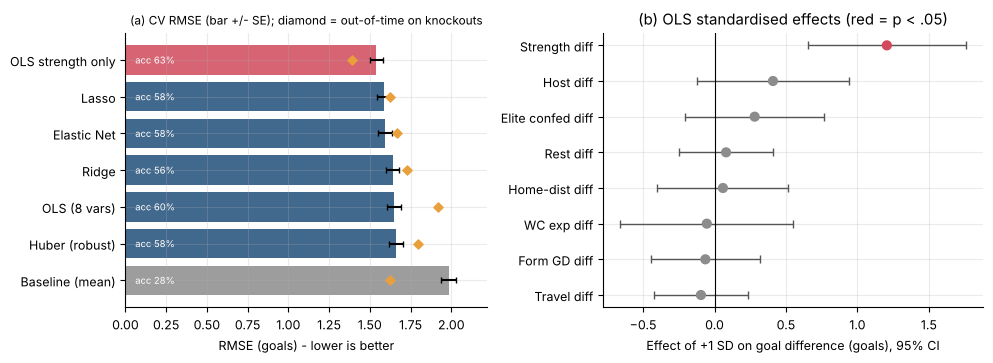

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.7), gridspec_kw={"width_ratios": [1, 1.05]})
order = cv_table.sort_values("RMSE", ascending=False).index
cols_ = [C["grey"] if "Baseline" in m_ else C["accent"] if m_ == cv_table.index[0] else C["main"] for m_ in order]
ax[0].barh(order, cv_table.loc[order, "RMSE"], xerr=cv_table.loc[order, "RMSE_sd"] / np.sqrt(100),
           color=cols_, alpha=.85, capsize=2)
ax[0].scatter(oot.loc[order, "RMSE"], order, marker="D", c=C["gold"], zorder=3, s=22,
              label="Out-of-time RMSE (knockouts)")
for i, m_ in enumerate(order):
    ax[0].text(0.06, i, f"acc {cv_table.loc[m_, 'Outcome_acc']:.0%}", va="center", fontsize=6.8, color="white")
ax[0].set_xlim(0, max(cv_table.RMSE.max(), oot.RMSE.max()) * 1.12)
ax[0].set_xlabel("RMSE (goals) - lower is better")
ax[0].set_title("(a) CV RMSE (bar +/- SE); diamond = out-of-time on knockouts", fontsize=8.5)
sc = std_coef.sort_values("coef")
cl = [C["accent"] if p_ < .05 else C["grey"] for p_ in sc.p_value]
ax[1].errorbar(sc.coef, range(len(sc)), xerr=[sc.coef - sc.ci_low, sc.ci_high - sc.coef], fmt="none",
               ecolor="#555", capsize=3, lw=1)
ax[1].scatter(sc.coef, range(len(sc)), c=cl, s=40, zorder=3)
ax[1].axvline(0, c="black", lw=.8)
ax[1].set_yticks(range(len(sc))); ax[1].set_yticklabels([labels[i] for i in sc.index])
ax[1].set_xlabel("Effect of +1 SD on goal difference (goals), 95% CI")
ax[1].set_title("(b) OLS standardised effects (red = p < .05)")
plt.tight_layout(); plt.savefig("../figures/fig2_lr21_models.png", dpi=200, bbox_inches="tight"); plt.show()

## 8. Residual diagnostics and the tournament's biggest upsets
Out-of-fold predictions (from one 10-fold pass of Ridge) are used so that the "upset" ranking is
honest - each match is predicted by a model that never saw it.

In [12]:
print(ols.diagnostics().round(4))
from sklearn.model_selection import cross_val_predict, KFold
oof = cross_val_predict(models["Ridge"], X.values, y.values, cv=KFold(10, shuffle=True, random_state=7))
df["pred_oof"] = oof; df["resid_oof"] = y - oof
upsets = df.reindex(df.resid_oof.abs().sort_values(ascending=False).index).head(6)
upsets[["match_id", "stage", "team_a", "team_b", "goal_diff", "pred_oof", "resid_oof"]].round(2)

Breusch-Pagan LM    8.5675
BP p-value          0.3801
Shapiro-Wilk W      0.9844
SW p-value          0.2626
Durbin-Watson       1.9546
Skew                0.3658
Kurtosis            0.4064
dtype: float64


,match_id,stage,team_a,team_b,goal_diff,pred_oof,resid_oof
27,28,Group B,Canada,Qatar,6,0.43,5.57
8,9,Group E,Germany,Curaçao,6,1.67,4.33
65,66,Group I,Senegal,Iraq,5,0.77,4.23
35,36,Group F,Tunisia,Japan,-4,-0.32,-3.68
34,35,Group F,Netherlands,Sweden,4,0.39,3.61
93,94,Round of 16,USA,Belgium,-3,0.48,-3.48


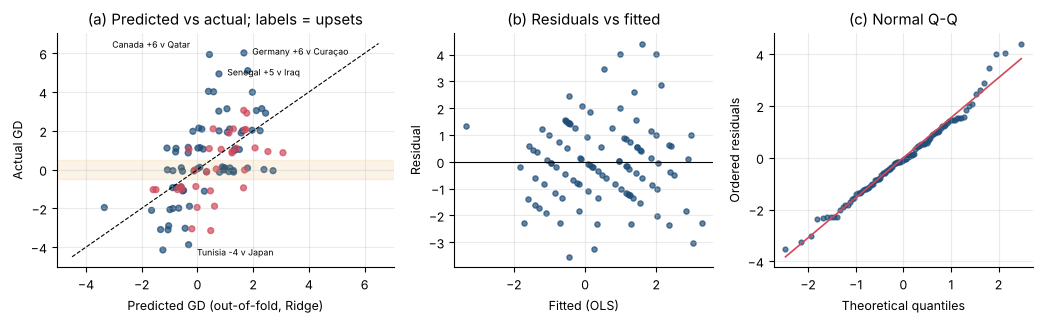

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(10.5, 3.3), gridspec_kw={"width_ratios": [1.3, 1, 1]})
ax[0].scatter(df.pred_oof, y + jit, s=18, alpha=.7, c=np.where(ko, C["accent"], C["main"]))
lim = [-4.5, 6.5]; ax[0].plot(lim, lim, c="black", lw=.8, ls="--")
ax[0].axhspan(-.5, .5, color=C["gold"], alpha=.12)
offs = [(-70, 4), (6, -1), (6, -2), (6, -6)]
for (_, r), o in zip(upsets.head(4).iterrows(), offs):
    ax[0].annotate(f"{r.team_a} {r.goal_diff:+d} v {r.team_b}", (r.pred_oof, r.goal_diff), fontsize=6.3,
                   xytext=o, textcoords="offset points")
ax[0].set_xlabel("Predicted GD (out-of-fold, Ridge)"); ax[0].set_ylabel("Actual GD")
ax[0].set_title("(a) Predicted vs actual; labels = upsets")
ax[1].scatter(ols.fitted, ols.resid, s=14, alpha=.7, c=C["main"]); ax[1].axhline(0, c="black", lw=.8)
ax[1].set_xlabel("Fitted (OLS)"); ax[1].set_ylabel("Residual"); ax[1].set_title("(b) Residuals vs fitted")
(osm, osr), (sl, ic, _) = stats.probplot(ols.resid, dist="norm")
ax[2].scatter(osm, osr, s=12, c=C["main"], alpha=.7); ax[2].plot(osm, sl * osm + ic, c=C["accent"], lw=1.2)
ax[2].set_xlabel("Theoretical quantiles"); ax[2].set_ylabel("Ordered residuals"); ax[2].set_title("(c) Normal Q-Q")
plt.tight_layout(); plt.savefig("../figures/fig3_lr21_diagnostics.png", dpi=200, bbox_inches="tight"); plt.show()

## 9. Save results for the report

In [14]:
res = {"n": int(len(df)), "ols_r2": ols.r2, "ols_adj_r2": ols.adj_r2, "ols_f": ols.f_stat, "ols_f_p": ols.f_p,
       "ols_aic": ols.aic, "coef_table": coef_table.reset_index().to_dict("records"),
       "std_coef": std_coef.reset_index().to_dict("records"), "vif": v.to_dict(),
       "cv_table": cv_table.reset_index().to_dict("records"), "oot": oot.reset_index().to_dict("records"),
       "ttests": ttests.to_dict("records"), "diagnostics": ols.diagnostics().to_dict(),
       "lasso_alpha": lasso_alpha, "ridge_alpha": ridge_alpha, "lasso_coefs": lasso_coefs.to_dict(),
       "upsets": upsets[["team_a", "team_b", "goal_diff", "pred_oof", "resid_oof", "stage"]].to_dict("records"),
       "corr_with_target": corr[TARGET].drop(TARGET).to_dict()}
json.dump(res, open("../results/lr21_results.json", "w"), indent=1, default=float)
print("saved")

saved
